# SSL and adaptive filtering: six findings worth keeping
**Session synthesis · 14 October 2026**

**SSL is useful in the tested vehicle. Training history changes the value of further
updates. We have not yet shown that the tested label-free signals can exploit that
opportunity reliably or cheaply.**

This is a selection of the experiments that changed our research direction, rather
than a chronological run log. It follows the session from day→night→day and smoothing
through budgeted admission, health measurements and adaptive batch mixtures.

| Finding | Consequence for a tunable filter |
|---|---|
| Night training improved day capability; returning day reduced both domains | Do not assume the regime switch identifies forgetting |
| Reversing history changes update utility at matched training age | State and training diet matter beyond update count |
| Gradual mixing gave transient protection but worse final capability | Smoothness alone is not a useful control objective |
| Content scores did not establish a lead over cheap pacing; local stopping headroom was small | Require measurable action value before fitting a predictor |
| Representation movement separated selected controls but failed future-harm prediction | A diagnostic is not yet a decision signal |
| Adaptive replay barely improved on fixed replay and cost more | Separate the value of memory from the value of adaptation |

**How to read the numbers.** The later primary score is accuracy after fine-tuning a
copied SSL encoder using 50 labeled support images, three support panels and 100
steps. Evaluation uses 400 balanced city/highway queries split across day and night.
This measures few-label adaptation capability, not an online supervised classifier.
Labels do not choose the online SSL training images. `pp` means percentage points.

The plots load saved, audited summaries. Rerunning this notebook performs no SSL
training, downloads, checkpoint writes or new model fits. Saved outputs can be read
without the local experiment caches.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "cafl4ds").is_dir() and (p / "outputs").is_dir())
RUNS = {
    "regime": "regime-windows/20261013-gpu",
    "history": "history-order/20261013-gpu",
    "smoothing": "diet-smoothing/20261013-gpu",
    "coverage": "coverage-admission/20261013-gpu",
    "health": "health-warning/20261013-gpu",
    "stopping": "stopping-headroom/20261014-cached",
    "mixture": "adaptive-mixture/20261014-gpu",
}
summaries = {
    name: json.loads((ROOT / "outputs" / run / "summary.json").read_text())
    for name, run in RUNS.items()
}
plt.rcParams.update({
    "figure.dpi": 120, "font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18,
})
COLORS = {"balanced": "#286b91", "A": "#bd6b29", "B": "#328264"}

def interval(ax, value, y, color, label=None):
    lo, hi = value["ci95_pp"]
    ax.plot([lo, hi], [y, y], color=color, linewidth=3, label=label)
    ax.scatter(value["mean_pp"], y, color=color, s=45, zorder=3)

print("Loaded seven completed studies. No learning or downloads are performed.")

Loaded seven completed studies. No learning or downloads are performed.


## 1. Useful SSL and later deterioration can coexist

The day→night→day pilot contradicted the simplest forgetting story. Day capability
**increased during night training**. Both domains then declined during returning-day
training, while final balanced capability remained **2.22pp above the warm model**.

That is evidence for useful SSL and a harmful later segment. It does not by itself
identify catastrophic forgetting caused by illumination. The follow-up included
continued-night footage, which also deteriorated: returning to day was not necessary
for harm in that local state.

The plotted means connect sparse checkpoints, not continuous trajectories. This
pilot has three optimization seeds on reused footage. Its intervals are conditional
seed intervals, not independent-drive confidence. The primary day decline is stronger
than the day decline seen by linear/kNN readers.

**Window insight:** full and uniform-half terminal states match exactly across
widths 32/128/512. Larger windows delay intermediate updates when they preserve the
same training batches; they need not change the final representation. A 512-frame
window had no updates in the first 256 night arrivals.

[Pilot and audits](../docs/experiments/phase1/slow-edge-regime-windows.md)

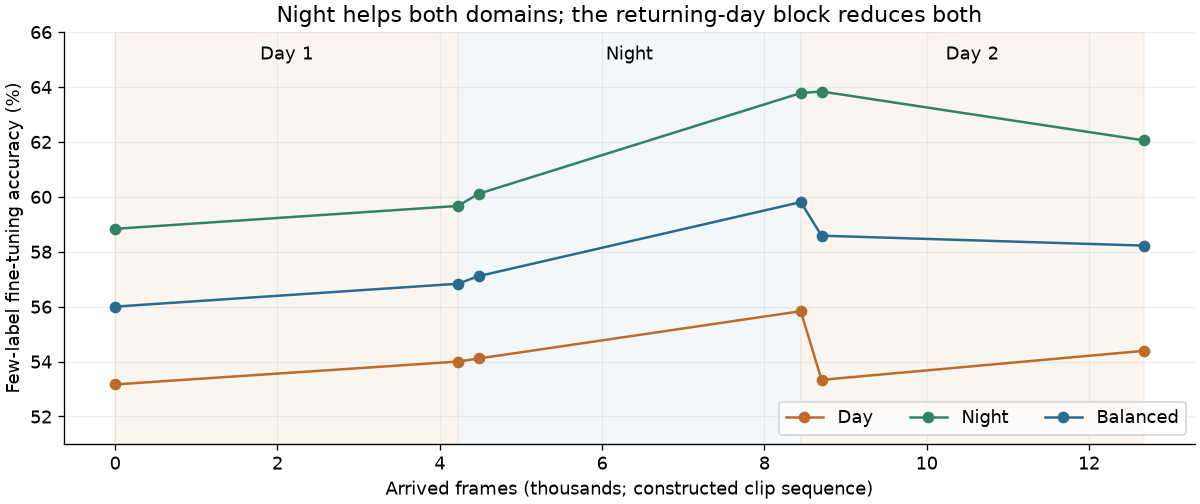

In [2]:
r = summaries["regime"]
trajectory = r["arms"]["w32/full"]["trajectory_accuracy_percent"]
clocks = [0, 4224, 4480, 8448, 8704, 12672]
records = [r["frozen_accuracy_percent"]] + [trajectory[str(c)] for c in clocks[1:]]
fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
for key, label in [("A", "Day"), ("B", "Night"), ("balanced", "Balanced")]:
    ax.plot(np.array(clocks) / 1000, [row[key] for row in records], "o-",
            color=COLORS[key], label=label)
for left, right, name, color in [(0, 4224, "Day 1", "#ead0ae"),
                                (4224, 8448, "Night", "#c7d8e9"),
                                (8448, 12672, "Day 2", "#ead0ae")]:
    ax.axvspan(left / 1000, right / 1000, color=color, alpha=.2)
    ax.text((left + right) / 2000, 65, name, ha="center")
ax.set(xlabel="Arrived frames (thousands; constructed clip sequence)",
       ylabel="Few-label fine-tuning accuracy (%)", ylim=(51, 66),
       title="Night helps both domains; the returning-day block reduces both")
ax.legend(loc="lower right", ncol=3)
plt.show()

### The full window/filter comparison

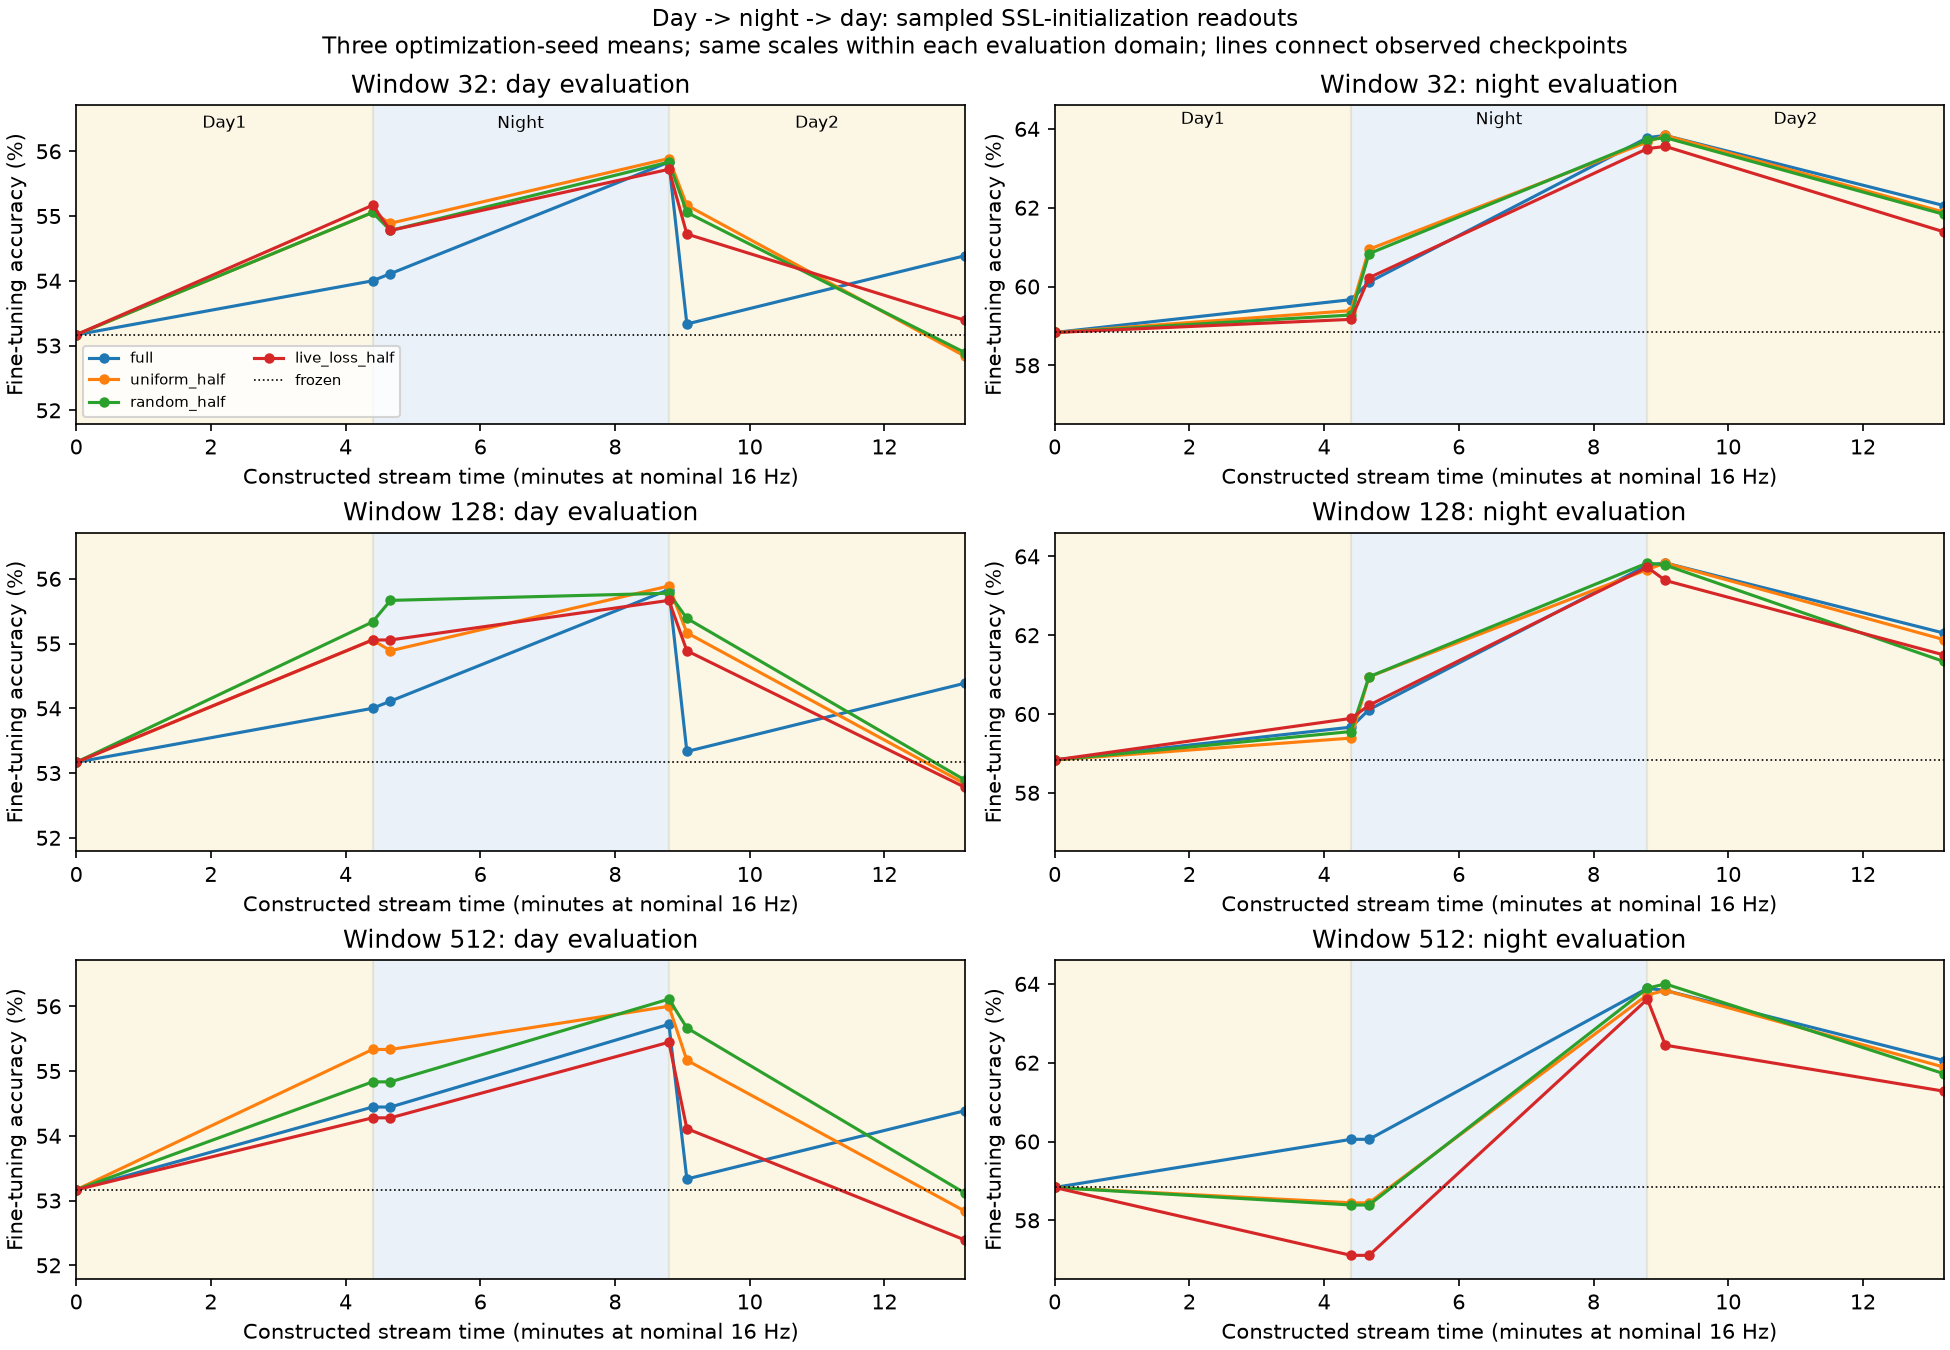

**Legend:**

- **full:** admit all 12,672 arriving frames for online SSL, giving 396 updates
  of batch size 32. This is the full-rate training reference, with no historical replay.
  It does not mean supervised training, training to convergence, or a larger model.
- **uniform_half:** train on evenly spaced half-window positions.
- **random_half:** train on a randomly selected half of each window.
- **live_loss_half:** train on the half with the highest pre-update reconstruction loss.
- **frozen:** keep the warm encoder unchanged during the online stream.

Every half arm admits 6,336 frames and performs 198 updates. The window width
(32, 128 or 512 arrivals) determines when selection closes and batches become
available; it is not the optimizer batch size, which remains 32. Evaluation still
fine-tunes a separate copy of each checkpoint, including the frozen reference.

Read each row as one window width, and each column as one evaluation domain.
Points are three-seed means; connecting lines interpolate between sparse observations.
The time axis is the constructed nominal-16Hz sequence, not one continuous drive.
The flat early-night segment at width 512 reflects waiting for a window to close.
These half-filter curves are fixed-rule policies, distinct from the later adaptive
replay-fraction experiment in finding 6.

## 2. History changes the value of training—even at the same update count

This is the strongest direct result for a state-aware filter. Two parents saw the
**same 8,448 historical images and 264 updates**, ordered day→night or night→day.
Each then received the same new day footage. Updating versus holding was strongly
harmful after day→night and approximately neutral after night→day.

The difference between those action responses was **+2.93pp [2.49, 3.38]** on
12 new day blocks, passing the frozen history-effect rule. Linear and kNN readers
corroborated the interaction. Optimization seeds and support panels were averaged
within each block; capture-session independence remains unknown.

**Implication:** update count alone does not explain utility. The history of the
training diet matters. However, this was a harmful-to-neutral change, not a qualified
reversal from “hold” to “train.” It demonstrates a control opportunity's structure,
not a working controller. Absolute parent quality also differed; the interaction
compares each action with its own parent's hold baseline.

[Matched-history experiment](../docs/experiments/phase1/slow-edge-history-order.md)

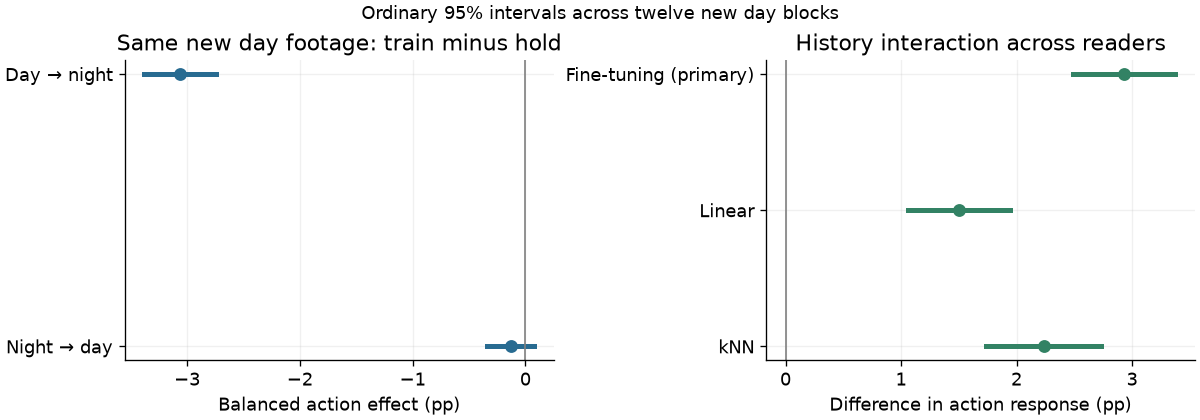

In [3]:
h = summaries["history"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for y, (cell, label) in enumerate([("DN_day", "Day → night history"),
                                  ("ND_day", "Night → day history")]):
    value = h["cells"][cell]["contrasts"]["finetune"]["unadjusted"]["balanced"]
    interval(axes[0], value, y, COLORS["balanced"])
axes[0].set_yticks([0, 1], ["Day → night", "Night → day"])
axes[0].set(title="Same new day footage: train minus hold",
            xlabel="Balanced action effect (pp)")
for y, reader in enumerate(["finetune", "linear", "knn"]):
    value = h["ND_minus_DN_action_response"]["day"][reader]["unadjusted"]["balanced"]
    interval(axes[1], value, y, COLORS["B"])
axes[1].set_yticks([0, 1, 2], ["Fine-tuning (primary)", "Linear", "kNN"])
axes[1].set(title="History interaction across readers",
            xlabel="Difference in action response (pp)")
fig.suptitle("Ordinary 95% intervals across twelve new day blocks", fontsize=11)
for ax in axes:
    ax.axvline(0, color="gray", linewidth=1)
    ax.invert_yaxis()
plt.show()

## 3. Smoothing the diet did not solve the harmful-update problem

Gradual night/day mixing and abrupt replay used exactly the same **272 old images
in the same sequence**, 3,952 current exposures and 132 updates. Only their scheduling
and current-image identities differed. The gradual taper did not establish a lead
over abrupt replay. On returning day it was **0.94pp worse than current-only training**
in balanced capability, with **2.56pp less day capability** despite a small night gain.

The early day advantage disappeared by the final checkpoint. Hold retained the
strongest balanced mean. Continued-night controls also declined, supporting a local
“additional training can harm” explanation rather than a switch-only explanation.

**Implication:** a smoother distribution transition is not automatically a safer
learning transition. Protecting one domain can reduce another. This closes the tested
taper, not all memory or smoothing mechanisms. The curves below show means from
three reused-history seeds, not source-independent confirmation.

[Smoothing experiment](../docs/experiments/phase1/slow-edge-diet-smoothing.md)

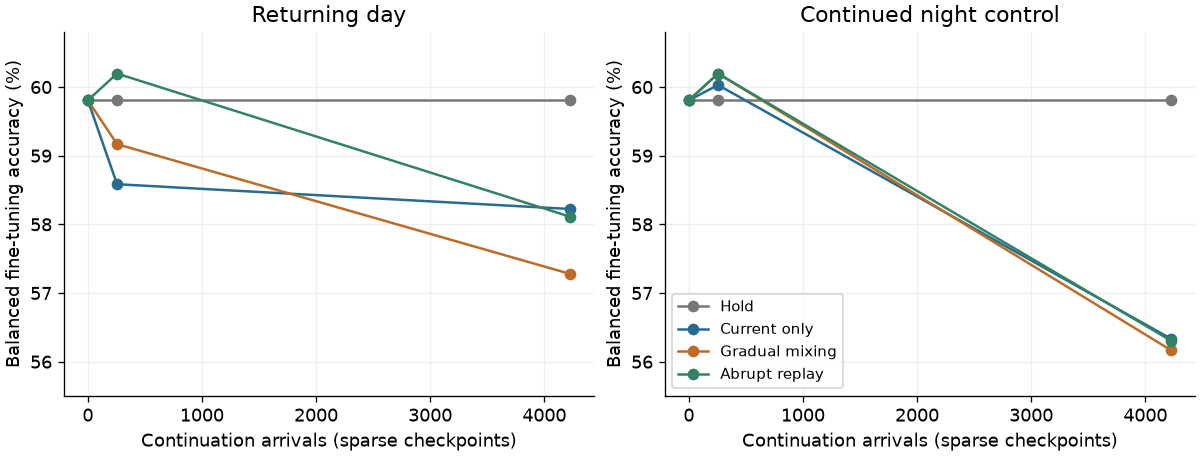

In [4]:
s = summaries["smoothing"]["contexts"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
for ax, context, title in zip(axes, ["day2", "night2"],
                              ["Returning day", "Continued night control"]):
    for action, label, color in [("hold", "Hold", "#777777"),
                                 ("full", "Current only", "#286b91"),
                                 ("smooth", "Gradual mixing", "#bd6b29"),
                                 ("abrupt", "Abrupt replay", "#328264")]:
        values = s[context]["means_accuracy_percent"][action]
        ax.plot([0, 256, 4224], [values["256"]["balanced"] if action == "hold"
                else s[context]["means_accuracy_percent"]["hold"]["256"]["balanced"],
                values["256"]["balanced"], values["4224"]["balanced"]],
                "o-", label=label, color=color)
    ax.set(title=title, xlabel="Continuation arrivals (sparse checkpoints)",
           ylabel="Balanced fine-tuning accuracy (%)", ylim=(55.5, 60.8))
axes[1].legend(loc="lower left", fontsize=9)
plt.show()

## 4. Cheap pacing is hard to beat; apparent adaptive headroom can shrink

Accepted-history coverage admission gave only **+0.051pp versus uniform** and
**+0.079pp versus random** at the same 192-update budget. Neither lead qualified.
Coverage saved about 41% of measured prepared processing versus full training,
but charged feature scoring made it slower than the equally budgeted cheap controls.
Domain quality guards failed. Early stopping had the highest balanced mean in this
collection; that does not certify a retention-safe rule.

A separate cached local stopping analysis asked a more basic question: even with
hindsight, how much benefit was available? Choosing the best of 0/4/8/16/32 additional
updates gave **+0.378pp** on the same queries used for selection. Choosing on one
query half and evaluating on the other reduced this to **+0.145/+0.142pp**, with
adjusted intervals crossing zero. One direction had four domain losses above 1pp.

**Implication:** the budget is an allowance, not an obligation to train. But first
establish enough transferable benefit from choosing actions to justify the overhead
of a predictor. These query halves were already-used evaluation data, not fresh tests.
The local stopping analysis does not bound other batches, resume schedules or horizons.

[Coverage admission](../docs/experiments/phase1/slow-edge-coverage-admission.md) ·
[Stopping headroom](../docs/experiments/phase1/slow-edge-stopping-headroom.md)

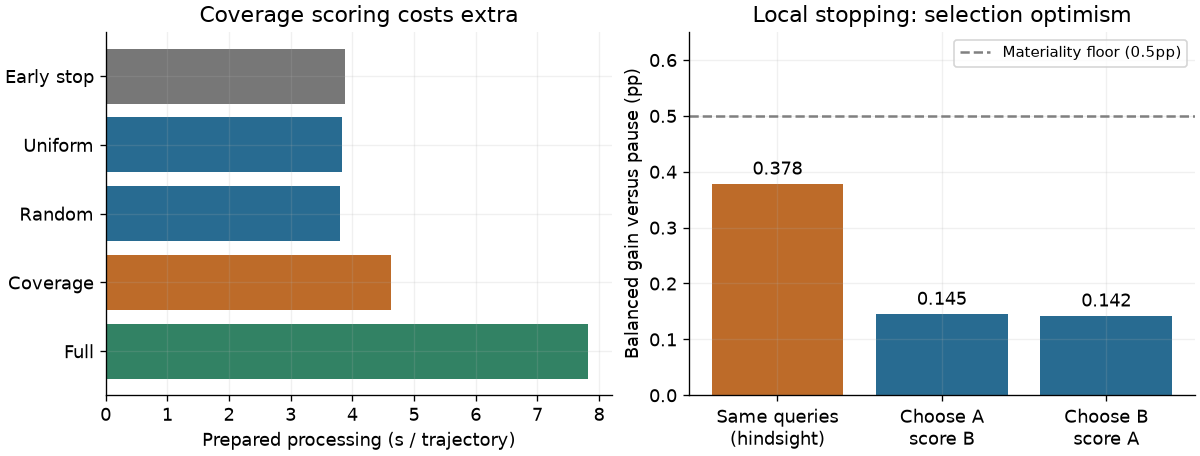

In [5]:
c = summaries["coverage"]
t = summaries["stopping"]["primary"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
arms = ["early_stop", "uniform", "random", "coverage", "full"]
times = [c["processing_seconds"][a] for a in arms]
axes[0].barh(["Early stop", "Uniform", "Random", "Coverage", "Full"], times,
             color=["#777777", "#286b91", "#286b91", "#bd6b29", "#328264"])
axes[0].invert_yaxis()
axes[0].set(title="Coverage scoring costs extra", xlabel="Prepared processing (s / trajectory)")
values = [t["hindsight"]["retention_aware"]["evaluation"]["mean_effect_vs_hold"][0]]
values += [t["query_half_folds"][f]["oracle"]["mean_effect_vs_hold"][0]
           for f in ["A_to_B", "B_to_A"]]
bars = axes[1].bar(["Same queries\n(hindsight)", "Choose A\nscore B", "Choose B\nscore A"],
                    values, color=["#bd6b29", "#286b91", "#286b91"])
axes[1].bar_label(bars, fmt="%.3f", padding=3)
axes[1].axhline(.5, color="gray", linestyle="--", label="Materiality floor (0.5pp)")
axes[1].set(title="Local stopping: selection optimism", ylabel="Balanced gain versus pause (pp)",
            ylim=(0, .65))
axes[1].legend(fontsize=9)
plt.show()

## 5. Representation movement is a diagnostic, not yet an alarm

CKA measures similarity between feature geometries on a fixed image bank. More CKA
drift means more representation change; it does not specify whether change is good.
Selected harmful historical controls moved more than a selected beneficial control.
That was interesting but insufficient for a usable health signal.

The prospective test held out entire histories and predicted **damage still ahead**
after update eight, relative to stopping there. Adding accumulated CKA increased
observed prediction error **29.63% versus count/loss**, and only two of six fitted
risk slopes had the intended sign. Improvement did not qualify. Beneficial and harmful
future outcomes were both present, so failure was not just a lack of varied targets.

An early-return example had high drift after 16 updates but recovered some balanced
capability with more training. This is why detecting movement or damage already
incurred is different from predicting the consequence of the next action.

**Implication:** retain geometry as instrumentation. The tested CKA alarm is
unqualified; no threshold follows from selected-control separation. Other health
signals remain open. These fits use only six reused histories.

[Prospective health test](../docs/experiments/phase1/slow-edge-health-warning.md)

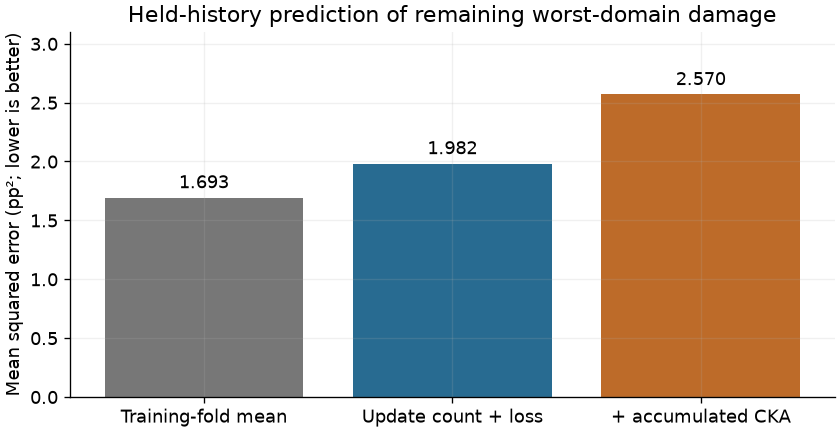

In [6]:
w = summaries["health"]["forecasts"]["8"]
models = w["models"]
values = [models[k]["mse"] for k in ["mean", "count_loss", "cka"]]
fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
bars = ax.bar(["Training-fold mean", "Update count + loss", "+ accumulated CKA"], values,
              color=["#777777", "#286b91", "#bd6b29"])
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set(title="Held-history prediction of remaining worst-domain damage",
       ylabel="Mean squared error (pp²; lower is better)", ylim=(0, 3.1))
plt.show()

## 6. Memory helps the mean; adaptive timing has not earned its extra cost

The final experiment compared current-only, fixed replay, random replay timing and
context-adaptive replay timing across six reused histories and three seeds. Every arm
used 192 updates. The three replay arms consumed the **same 1,472 old-image exposures
in matched sequences**, isolating timing and current-image admission from total old dose.

Adaptive balanced capability was **57.05% versus fixed 56.93%**. Its +0.12pp advantage
had an adjusted interval **[−0.26, +0.50]**, so no adaptive content lead qualified.
The balanced gain versus warm was **+1.05pp [0.05, 2.04]**, adjusted: useful SSL
remains supported. Day-domain retention did not qualify.

Most observed night improvement was already present with fixed replay. Adaptive
processing was **73% higher than fixed**, including the frozen reference forwards.
Quotas overrode about 41% of context proposals; this was a constrained adaptive rule.

**Implication:** distinguish “include some past data” from “adapt the fraction using
context.” The tested controller has little established value beyond fixed mixing.
Processing figures exclude decoding, readouts, forensic audits and deployed pixel
retention. Fixed replay itself has not been certified as universally retention-safe.

[Adaptive mixture experiment](../docs/experiments/phase1/slow-edge-adaptive-mixture.md)

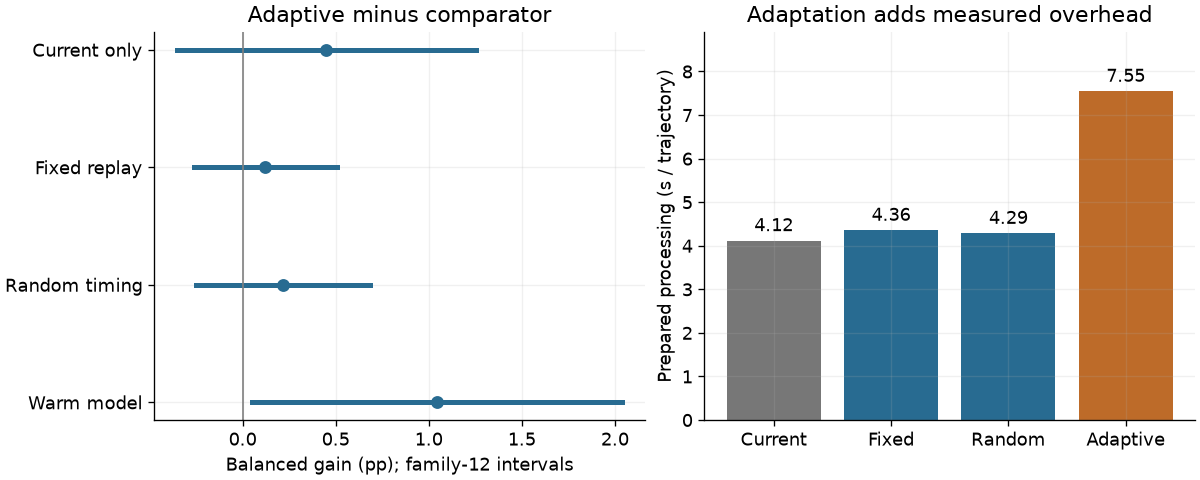

In [7]:
m = summaries["mixture"]
terminal = m["horizons"]["terminal"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for y, ref in enumerate(["current", "fixed", "random", "warm"]):
    value = terminal["contrasts"][ref]["finetune"]["balanced"]["adjusted"]
    interval(axes[0], value, y, COLORS["balanced"])
axes[0].set_yticks(range(4), ["Current only", "Fixed replay", "Random timing", "Warm model"])
axes[0].invert_yaxis()
axes[0].axvline(0, color="gray", linewidth=1)
axes[0].set(title="Adaptive minus comparator", xlabel="Balanced gain (pp); family-12 intervals")
arms = ["current", "fixed", "random", "adaptive"]
keys = ["gather_seconds", "reference_seconds", "decision_seconds", "ssl_seconds", "reservoir_plan_seconds"]
times = [sum(m["costs_per_trajectory"][a][k] for k in keys) for a in arms]
bars = axes[1].bar(["Current", "Fixed", "Random", "Adaptive"], times,
                   color=["#777777", "#286b91", "#286b91", "#bd6b29"])
axes[1].bar_label(bars, fmt="%.2f", padding=3)
axes[1].set(title="Adaptation adds measured overhead", ylabel="Prepared processing (s / trajectory)",
            ylim=(0, max(times) * 1.18))
plt.show()

## What survives all six findings

Continue SSL, but make **action utility** the bridge from measurements to filtering.
A useful filter must choose training that improves capability, protect day and night
separately, and justify its measurement cost against simple hold, pacing and fixed
replay controls. State and history are relevant; the tested loss/coverage/CKA/context
recipes have not yet established a reliable way to exploit them.

The important open question is which batch construction creates a material,
reproducible beneficial-versus-harmful choice. That is a research question, not a
validated controller or an instruction to launch another experiment.

**Limits that apply throughout:** real chronology is preserved within clips, but
regime streams concatenate different drives. Capture sessions are unknown. Many
later tests reuse source histories, warm states, support panels and queries. Three
seeds are optimization replicates, not three independent datasets. Fine-tuning,
linear and kNN can disagree; choose the target before inspecting outcomes. Balanced
gains can conceal a domain loss. Cross-study scores should not be pooled as one
estimate. Exact replay and numerical audits support implementation integrity, not
independent-session generalization. Broad phase and deployment gates remain unchanged.

### Evidence and reproducibility

The table below records the exact summary files used for every plotted number.
Detailed study links above contain protocols, interval definitions and audit scope.
Only the cited findings are selected; this notebook does not supersede the full logbook.

In [8]:
rows = ["| Study | Saved summary | SHA-256 |", "|---|---|---|"]
for name, run in RUNS.items():
    path = ROOT / "outputs" / run / "summary.json"
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    rows.append(f"| {name} | [summary](../outputs/{run}/summary.json) | `{digest}` |")
print("\n".join(rows))
assert summaries["history"]["primary_history_effect_qualified"]
assert not summaries["health"]["qualified"]
assert not summaries["stopping"]["primary"]["investigation_screen_passed"]
assert summaries["mixture"]["gates"]["useful_ssl"]
assert not summaries["mixture"]["adaptive_mixture_qualified"]
print("Recorded verdicts agree with the saved summaries.")

| Study | Saved summary | SHA-256 |
|---|---|---|
| regime | [summary](../outputs/regime-windows/20261013-gpu/summary.json) | `ebc1471ced02e3fa51f73f1de90ced0b0d347e9b1c48dd7c612c1f68e277c101` |
| history | [summary](../outputs/history-order/20261013-gpu/summary.json) | `93a72c7c28227005408cea1b4e3abd5122a5c82de756cd2509378922f7870657` |
| smoothing | [summary](../outputs/diet-smoothing/20261013-gpu/summary.json) | `d73f81df1b100dbdaccd93c30a6343ba95ef1eae777c3ac26edfa5d128db9ee0` |
| coverage | [summary](../outputs/coverage-admission/20261013-gpu/summary.json) | `87fcf9878e7be7a4a0fc9a7f89d990eca4a5ca0d24beb96bcec620883d4bebb1` |
| health | [summary](../outputs/health-warning/20261013-gpu/summary.json) | `60d6a33aa52e1cf29cb8285aa6080f6eee82ab9ac031cd9247b22e89128086ef` |
| stopping | [summary](../outputs/stopping-headroom/20261014-cached/summary.json) | `3cd60ce49968a41c454b85f126d4d56b0f50a9866c2b0c4ce36b26a4c070eccb` |
| mixture | [summary](../outputs/adaptive-mixture/20261014-gpu/